# Actividad 4 – Simulación de los cajeros de un parqueadero

**Asignatura:** Simulación  
**Tema:** Colas, estado estable y período transitorio  

En este cuaderno voy a simular los cajeros de pago del parqueadero de **Supercentro** y comparar si los tres cajeros actuales son suficientes. También analizaré cómo cambia el promedio de espera al quitar el período inicial de la simulación.

**Cómo utilizarlo:** en Google Colab selecciono **Entorno de ejecución → Ejecutar todas**. Las tablas y las gráficas se generan automáticamente. Los datos no pertenecen a un parqueadero real: son los del enunciado y algunos supuestos explicados abajo.

## 1. Datos y supuestos que utilicé

La tabla del profesor tiene las medias de servicio y llegada para cada tipo de usuario. El enunciado indica **25 % rápidos**, **20 % normales** y **55 % entre lentos y muy lentos**, pero no dice cómo repartir ese último porcentaje. Para el modelo principal supuse **27,5 % lentos y 27,5 % muy lentos**. Más adelante pruebo otra distribución para ver si la conclusión cambia.

**Importante sobre las llegadas:** la tabla da cuatro medias de llegada, pero no aclara si hay cuatro corrientes independientes o una sola corriente de vehículos. Para respetar las proporciones de usuarios y tener un proceso global de Poisson, utilizo una sola llegada exponencial con media **ponderada de las cuatro medias**. Después de cada llegada elijo el tipo según las probabilidades. Es una **decisión de modelado**, no significa que cada tipo mantenga individualmente la media de llegada de la tabla.

Cada cajero tiene su propia fila, atiende a una persona a la vez, no hay cambio de fila ni deserción. Como el enunciado no especifica cuántas horas opera el parqueadero, las corridas se miden por **cantidad de vehículos** y no se presentan como jornadas de ocho horas. Los tiempos de atención son exponenciales según la categoría. Como hay distintas medias de servicio, se trata de una **aproximación al esquema M/M/1 por cajero**; no es un M/M/1 homogéneo exacto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as distribucion_t
from collections import deque

SEMILLA = 2026
TIPOS = np.array(['Rápido', 'Normal', 'Lento', 'Muy lento'])
SERVICIO_MEDIO = np.array([1.0, 3.0, 4.0, 6.0])
LLEGADA_MEDIA = np.array([3.0, 3.0, 5.0, 7.0])
PROB = np.array([0.25, 0.20, 0.275, 0.275])
NUM_CAJEROS = 3

assert np.isclose(PROB.sum(), 1.0)
MEDIA_ENTRE_LLEGADAS = float(np.dot(PROB, LLEGADA_MEDIA))
MEDIA_SERVICIO = float(np.dot(PROB, SERVICIO_MEDIO))

parametros = pd.DataFrame({
    'Tipo': TIPOS, 'Servicio medio (min)': SERVICIO_MEDIO,
    'Llegada media de referencia (min)': LLEGADA_MEDIA,
    'Probabilidad': PROB
})
display(parametros)
print(f'Media global entre llegadas (supuesto): {MEDIA_ENTRE_LLEGADAS:.2f} min')
print(f'Media global teórica de servicio: {MEDIA_SERVICIO:.2f} min')
print(f'Utilización aproximada por cajero con 3 cajas: '
      f'{MEDIA_SERVICIO/(NUM_CAJEROS*MEDIA_ENTRE_LLEGADAS):.1%}')

,Tipo,Servicio medio (min),Llegada media de referencia (min),Probabilidad
0,Rápido,1.0,3.0,0.250
1,Normal,3.0,3.0,0.200
2,Lento,4.0,5.0,0.275
3,Muy lento,6.0,7.0,0.275


Media global entre llegadas (supuesto): 4.65 min
Media global teórica de servicio: 3.60 min
Utilización aproximada por cajero con 3 cajas: 25.8%


## 2. Programar la llegada de vehículos y las filas de los cajeros

Primero genero los vehículos y sus tiempos de atención. Luego recorro las llegadas en orden. Cada cliente se queda en la fila que eligió. Para la operación normal del parqueadero supongo que entra a la **fila con menos personas**; si hay empate, reparto la elección. También puedo ensayar asignar cajero al azar para comparar una estrategia menos organizada.

El modelo guarda el cajero elegido, el inicio y final de atención y los tiempos de espera. Esto permite verificar que dos vehículos no sean atendidos simultáneamente por la misma caja.

In [2]:
def generar_vehiculos(cantidad, semilla, probabilidades=PROB, intensidad=1.0):
    """Crea vehículos con una sola corriente de llegadas exponenciales."""
    rng = np.random.default_rng(semilla)
    probabilidades = np.asarray(probabilidades, dtype=float)
    media_global = float(np.dot(probabilidades, LLEGADA_MEDIA))
    tipos = rng.choice(len(TIPOS), size=cantidad, p=probabilidades)
    entre_llegadas = rng.exponential(media_global / intensidad, size=cantidad)
    llegadas = np.cumsum(entre_llegadas)
    servicios = rng.exponential(SERVICIO_MEDIO[tipos])
    return pd.DataFrame({
        'vehiculo': np.arange(1, cantidad + 1),
        'tipo': TIPOS[tipos],
        'llegada_min': llegadas,
        'servicio_min': servicios
    })


def simular_cajeros(vehiculos, cantidad_cajeros=3, estrategia='fila_corta', semilla=0):
    """Una fila FIFO por cajero. No hay cambio de fila ni deserción."""
    rng = np.random.default_rng(semilla)
    filas = [deque() for _ in range(cantidad_cajeros)]
    disponible = np.zeros(cantidad_cajeros)
    resultado = []

    for v in vehiculos.itertuples(index=False):
        llegada = float(v.llegada_min)
        # Saco de cada fila a quienes ya terminaron su atención.
        for fila in filas:
            while fila and fila[0] <= llegada:
                fila.popleft()

        if estrategia == 'fila_corta':
            menor = min(len(fila) for fila in filas)
            candidatos = [j for j, fila in enumerate(filas) if len(fila) == menor]
            cajero = candidatos[(int(v.vehiculo) - 1) % len(candidatos)]
        elif estrategia == 'aleatoria':
            cajero = int(rng.integers(0, cantidad_cajeros))
        else:
            raise ValueError('Estrategia no reconocida')

        inicio = max(llegada, disponible[cajero])
        fin = inicio + float(v.servicio_min)
        disponible[cajero] = fin
        filas[cajero].append(fin)
        resultado.append((int(v.vehiculo), v.tipo, llegada, float(v.servicio_min),
                          cajero + 1, inicio, fin, inicio - llegada))

    return pd.DataFrame(resultado, columns=[
        'vehiculo', 'tipo', 'llegada_min', 'servicio_min',
        'cajero', 'inicio_min', 'fin_min', 'espera_min'
    ])

# Prueba corta para comprobar la estructura
prueba = generar_vehiculos(12, SEMILLA)
resultado_prueba = simular_cajeros(prueba, 3)
display(resultado_prueba.head(8).round(2))

,vehiculo,tipo,llegada_min,servicio_min,cajero,inicio_min,fin_min,espera_min
0,1,Rápido,6.38,1.29,1,6.38,7.67,0.0
1,2,Lento,8.47,4.80,2,8.47,13.27,0.0
2,3,Lento,9.24,3.24,1,9.24,12.48,0.0
3,4,Normal,11.80,5.70,3,11.80,17.50,0.0
4,5,Normal,13.09,1.20,1,13.09,14.29,0.0
5,6,Muy lento,17.43,15.65,2,17.43,33.08,0.0
6,7,Muy lento,19.12,5.95,1,19.12,25.07,0.0
7,8,Rápido,24.01,0.93,3,24.01,24.94,0.0


## 3. Buscar el estado estable con la técnica del promedio

Para estudiar si el modelo se estabiliza, hago **20 corridas piloto independientes**, cada una con **2.400 vehículos**. Uso como variable el **tiempo de espera en fila**.

Divido cada corrida en bloques de 50 vehículos. Calculo el promedio de espera de cada bloque y luego el promedio de esos bloques entre todas las corridas: esta es una aplicación sencilla de la idea del **método gráfico de Welch**. Para quitar algo de ruido, suavizo cinco bloques cercanos. Comparo la curva con el promedio final de referencia y marco el primer tramo que permanece suficientemente cerca durante varios bloques.

El umbral de cercanía es un **criterio práctico propuesto para el ejercicio**. La gráfica ayuda a evaluar la estabilidad, pero por sí sola no garantiza matemáticamente que exista un estado estacionario. En un sistema con poca congestión es posible que el efecto de empezar con las filas vacías sea pequeño.

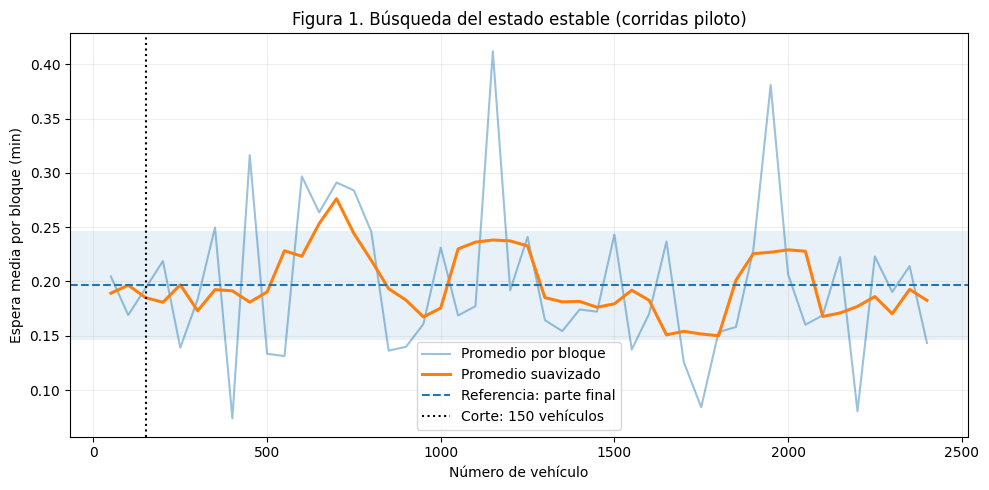

Corridas piloto: 20
Promedio de referencia: 0.197 min
Tolerancia adoptada: 0.05 min
Vehículos iniciales que se excluyen: 150
El criterio gráfico encontró un tramo cercano al promedio de referencia.


In [3]:
NUM_PILOTOS = 20
CLIENTES_PILOTO = 2400
TAM_BLOQUE = 50

series_piloto = []
for r in range(NUM_PILOTOS):
    veh = generar_vehiculos(CLIENTES_PILOTO, SEMILLA + 10000 + r)
    datos_r = simular_cajeros(veh, 3)
    serie = datos_r['espera_min'].to_numpy()
    series_piloto.append(serie.reshape(-1, TAM_BLOQUE).mean(axis=1))

# Promedio por bloque entre todas las corridas piloto
media_bloques = np.mean(series_piloto, axis=0)
suave = pd.Series(media_bloques).rolling(5, center=True, min_periods=1).mean().to_numpy()
referencia = float(np.mean(suave[-12:]))
tolerancia = max(0.05, 0.20 * referencia)

posicion = None
for i in range(2, len(suave)-7):
    if np.all(np.abs(suave[i:i+7] - referencia) <= tolerancia):
        posicion = i
        break

# Si no cumple la regla, no se debe afirmar que ya se estabilizó.
ESTABILIDAD_DETECTADA = posicion is not None
if ESTABILIDAD_DETECTADA:
    CORTE = (posicion + 1) * TAM_BLOQUE
else:
    # Corte de prueba conservador, solo para mostrar la comparación.
    CORTE = 600

fig, ax = plt.subplots(figsize=(10, 5))
x = (np.arange(len(media_bloques)) + 1) * TAM_BLOQUE
ax.plot(x, media_bloques, alpha=0.45, label='Promedio por bloque')
ax.plot(x, suave, linewidth=2.2, label='Promedio suavizado')
ax.axhline(referencia, linestyle='--', label='Referencia: parte final')
ax.axhspan(referencia-tolerancia, referencia+tolerancia, alpha=0.10)
ax.axvline(CORTE, color='black', linestyle=':', label=f'Corte: {CORTE} vehículos')
ax.set(title='Figura 1. Búsqueda del estado estable (corridas piloto)',
       xlabel='Número de vehículo', ylabel='Espera media por bloque (min)')
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig('Figura_01_Estado_Estable.png', dpi=200)
plt.show()

print('Corridas piloto:', NUM_PILOTOS)
print('Promedio de referencia:', round(referencia, 3), 'min')
print('Tolerancia adoptada:', round(tolerancia, 3), 'min')
print('Vehículos iniciales que se excluyen:', CORTE)
if ESTABILIDAD_DETECTADA:
    print('El criterio gráfico encontró un tramo cercano al promedio de referencia.')
else:
    print('AVISO: no se encontró estabilización clara con esta regla.')
    print('El corte es exploratorio: no debe presentarse como estado estable comprobado.')

## 4. Decidir cuántas réplicas ejecutar

El número de repeticiones no se elige solo porque la rúbrica pida varias. Uso primero la configuración actual, retiro los **primeros vehículos indicados por el análisis anterior** y calculo el intervalo de confianza del 95 % de la espera promedio entre corridas independientes.

Como criterio de precisión para este ejercicio, busco que la **semianchura del intervalo** sea como máximo el mayor de estos dos valores: **0,04 minutos** o **15 % de la media estimada**. Comienzo con 10 réplicas y amplío de cinco en cinco, con un máximo de 100. Este criterio es una decisión metodológica, no una norma del centro comercial.

,réplicas,espera_media,semianchura_IC95,meta_precision
0,10,0.208,0.027,0.04


Número de réplicas seleccionado: 10
Criterio de precisión cumplido: True


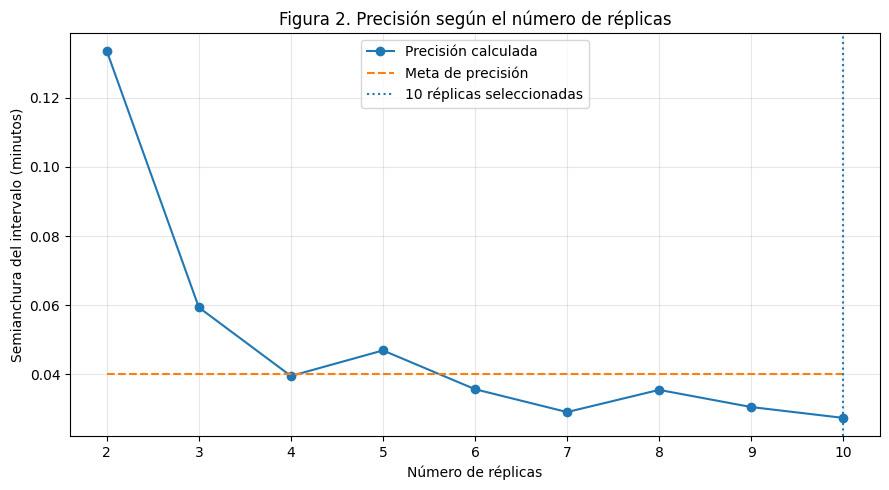

In [14]:
def intervalo_95(valores):
    a = np.asarray(valores, dtype=float)
    n = len(a)
    media = float(a.mean())
    if n < 2:
        return media, np.nan, np.nan
    error = float(distribucion_t.ppf(0.975, n - 1)
                  * np.std(a, ddof=1) / np.sqrt(n))
    return media, media - error, media + error

VEHICULOS_POR_REPLICA = 2000
MAX_REPLICAS = 100
medias_previas = []
control_precision = []
NUM_REPLICAS = MAX_REPLICAS
PRECISION_ALCANZADA = False

for replica in range(1, MAX_REPLICAS + 1):
    veh = generar_vehiculos(VEHICULOS_POR_REPLICA, SEMILLA + 20000 + replica)
    df = simular_cajeros(veh, 3)
    medias_previas.append(df['espera_min'].iloc[CORTE:].mean())
    if replica >= 10 and replica % 5 == 0:
        media, li, ls = intervalo_95(medias_previas)
        semianchura = (ls - li) / 2
        meta = max(0.04, 0.15 * media)
        control_precision.append((replica, media, semianchura, meta))
        if semianchura <= meta:
            NUM_REPLICAS = replica
            PRECISION_ALCANZADA = True
            break

tabla_precision = pd.DataFrame(control_precision, columns=[
    'réplicas', 'espera_media', 'semianchura_IC95', 'meta_precision'
])
display(tabla_precision.round(3))
print('Número de réplicas seleccionado:', NUM_REPLICAS)
print('Criterio de precisión cumplido:', PRECISION_ALCANZADA)
if not PRECISION_ALCANZADA:
    print('AVISO: se llegó al máximo sin cumplir la precisión fijada.')


# Comparo la precisión desde 2 hasta 10 réplicas
datos_grafica = []

for n in range(2, len(medias_previas) + 1):
    media, inferior, superior = intervalo_95(medias_previas[:n])
    semianchura = (superior - inferior) / 2
    meta = max(0.04, 0.15 * media)
    datos_grafica.append([n, semianchura, meta])

evolucion = pd.DataFrame(
    datos_grafica,
    columns=['replicas', 'semianchura', 'meta']
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(evolucion['replicas'], evolucion['semianchura'],
        marker='o', label='Precisión calculada')

ax.plot(evolucion['replicas'], evolucion['meta'],
        linestyle='--', label='Meta de precisión')

ax.axvline(NUM_REPLICAS, linestyle=':',
           label=f'{NUM_REPLICAS} réplicas seleccionadas')

ax.set_title('Figura 2. Precisión según el número de réplicas')
ax.set_xlabel('Número de réplicas')
ax.set_ylabel('Semianchura del intervalo (minutos)')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig('Figura_02_Numero_Replicas.png', dpi=200)
plt.show()




**Análisis de la figura 2**

En esta gráfica observé cómo cambia la precisión de los resultados al aumentar la cantidad de réplicas. Al principio, el intervalo es más amplio, pero después se va reduciendo, aunque presenta algunas variaciones.

Con 10 réplicas obtuve una semianchura de 0,027 minutos, inferior al límite de 0,04 minutos establecido para el ejercicio. Por esta razón, utilicé 10 réplicas para comparar los diferentes escenarios del parqueadero.

## 5. Ejecutar las réplicas y comparar estrategias

Ahora uso el número de réplicas calculado. Para comparar justamente las estrategias, en cada réplica uso los **mismos tipos de clientes y los mismos tiempos de servicio**. Las configuraciones son:

- **3 cajas, fila más corta:** situación de referencia con distribución organizada.
- **3 cajas, elección aleatoria:** para ver qué pasa si no se orienta a los usuarios.
- **4 cajas, fila más corta:** alternativa con un equipo adicional.
- **3 cajas, demanda triple:** escenario hipotético de alta afluencia.
- **4 cajas, demanda triple:** comprobar si el cajero adicional ayuda en ese pico.

El incremento de demanda es **una prueba de estrés**, no un dato real del centro comercial.

In [5]:
ESCENARIOS = [
    ('3 cajas · fila más corta', 3, 'fila_corta', 1.0),
    ('3 cajas · elección aleatoria', 3, 'aleatoria', 1.0),
    ('4 cajas · fila más corta', 4, 'fila_corta', 1.0),
    ('3 cajas · demanda triple', 3, 'fila_corta', 3.0),
    ('4 cajas · demanda triple', 4, 'fila_corta', 3.0),
]

filas_replicas = []
filas_tipos = []
filas_cajeros = []
filas_antes_despues = []
muestra_vehiculos = None
muestra_calibracion = None

for replica in range(1, NUM_REPLICAS + 1):
    vehiculos = generar_vehiculos(VEHICULOS_POR_REPLICA, SEMILLA + 30000 + replica)
    if replica == 1:
        muestra_calibracion = vehiculos.copy()
    for nombre, cajeros, regla, intensidad in ESCENARIOS:
        # La demanda triple conserva los servicios y acorta los intervalos de llegada.
        entrada = vehiculos.copy()
        if intensidad != 1:
            entrada['llegada_min'] /= intensidad
        datos = simular_cajeros(entrada, cajeros, regla,
                               semilla=SEMILLA + 40000 + replica)
        if replica == 1 and nombre == '3 cajas · fila más corta':
            muestra_vehiculos = datos.iloc[:150].copy()

        sin_inicio = datos.iloc[CORTE:]
        filas_replicas.append({
            'replica': replica, 'escenario': nombre,
            'cajeros': cajeros, 'factor_demanda': intensidad,
            'espera_media_min': sin_inicio['espera_min'].mean(),
            'espera_p90_min': sin_inicio['espera_min'].quantile(.90),
            'proporcion_espera_mayor_5': (sin_inicio['espera_min'] > 5).mean(),
            'servicio_medio_min': sin_inicio['servicio_min'].mean()
        })
        if nombre == '3 cajas · fila más corta':
            filas_antes_despues.append({
                'replica': replica,
                'antes_min': datos['espera_min'].mean(),
                'despues_min': sin_inicio['espera_min'].mean()
            })
        for tipo in TIPOS:
            grupo = sin_inicio[sin_inicio['tipo'] == tipo]
            filas_tipos.append({
                'replica': replica, 'escenario': nombre, 'tipo': tipo,
                'cantidad': len(grupo),
                'espera_media_min': grupo['espera_min'].mean() if len(grupo) else 0
            })
        for j in range(1, cajeros + 1):
            grupo = sin_inicio[sin_inicio['cajero'] == j]
            filas_cajeros.append({
                'replica': replica, 'escenario': nombre, 'cajero': j,
                'usuarios': len(grupo),
                'servicio_medio_min': grupo['servicio_min'].mean() if len(grupo) else 0,
                'espera_media_min': grupo['espera_min'].mean() if len(grupo) else 0
            })

replicas = pd.DataFrame(filas_replicas)
por_tipo = pd.DataFrame(filas_tipos)
por_cajero = pd.DataFrame(filas_cajeros)
antes_despues = pd.DataFrame(filas_antes_despues)
print('Corridas por escenario:', NUM_REPLICAS)
print('Corridas totales:', len(replicas))
display(replicas.head().round(3))

Corridas por escenario: 10
Corridas totales: 50


,replica,escenario,cajeros,factor_demanda,espera_media_min,espera_p90_min,proporcion_espera_mayor_5,servicio_medio_min
0,1,3 cajas · fila más corta,3,1.0,0.163,0.000,0.012,3.466
1,1,3 cajas · elección aleatoria,3,1.0,1.505,5.313,0.103,3.466
2,1,4 cajas · fila más corta,4,1.0,0.037,0.000,0.003,3.466
3,1,3 cajas · demanda triple,3,3.0,3.969,12.968,0.270,3.466
4,1,4 cajas · demanda triple,4,3.0,0.896,3.135,0.066,3.466


## 6. Punto 1: ¿qué cajero tiene menor y mayor tiempo de atención?

Uso el **tiempo de servicio**, sin sumarle el tiempo que las personas esperan en la fila. Como los cajeros funcionan igual, una diferencia pequeña puede deberse a que atendieron distintos tipos de clientes.

,cajero,servicio_medio_min,espera_media_min,usuarios_promedio
0,1,3.50,0.20,624.6
1,2,3.56,0.18,603.7
2,3,3.58,0.18,621.7


Menor servicio promedio: cajero 1 (3.50 min)
Mayor servicio promedio: cajero 3 (3.58 min)


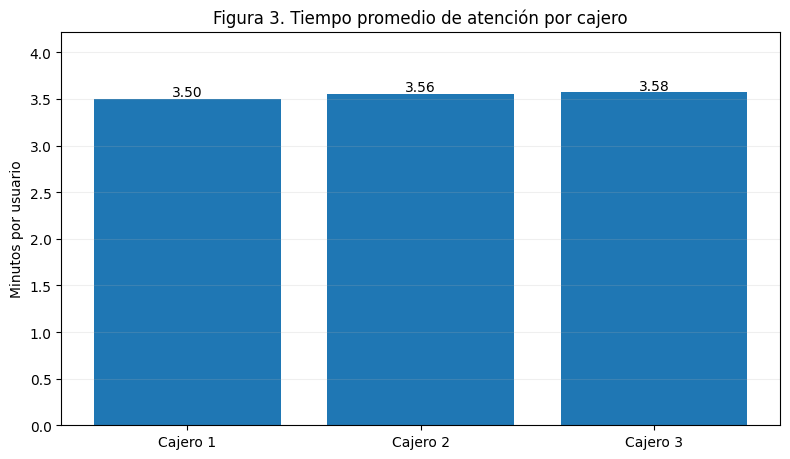

Análisis: la diferencia entre cajeros no demuestra que unos trabajen más rápido;
todos usan la misma regla de tiempo según el tipo de cliente.


In [6]:
cajeros_actuales = por_cajero.query('escenario == "3 cajas · fila más corta"')
tabla_cajeros = (cajeros_actuales.groupby('cajero', as_index=False)
                 .agg(servicio_medio_min=('servicio_medio_min','mean'),
                      espera_media_min=('espera_media_min','mean'),
                      usuarios_promedio=('usuarios','mean')))
display(tabla_cajeros.round(2))
menor = tabla_cajeros.loc[tabla_cajeros['servicio_medio_min'].idxmin()]
mayor = tabla_cajeros.loc[tabla_cajeros['servicio_medio_min'].idxmax()]
print(f'Menor servicio promedio: cajero {int(menor.cajero)} ({menor.servicio_medio_min:.2f} min)')
print(f'Mayor servicio promedio: cajero {int(mayor.cajero)} ({mayor.servicio_medio_min:.2f} min)')

fig, ax = plt.subplots(figsize=(8, 4.7))
ax.bar([f'Cajero {j}' for j in tabla_cajeros.cajero], tabla_cajeros.servicio_medio_min)
for i, v in enumerate(tabla_cajeros.servicio_medio_min):
    ax.text(i, v+0.025, f'{v:.2f}', ha='center')
ax.set_ylim(0, tabla_cajeros.servicio_medio_min.max()*1.18)
ax.set(title='Figura 3. Tiempo promedio de atención por cajero', ylabel='Minutos por usuario')
ax.grid(axis='y', alpha=.2); fig.tight_layout()
fig.savefig('Figura_03_Atencion_Cajeros.png', dpi=200)
plt.show()
print('Análisis: la diferencia entre cajeros no demuestra que unos trabajen más rápido;')
print('todos usan la misma regla de tiempo según el tipo de cliente.')

## 7. Punto 2: promedio de usuarios de cada tipo

Calculo cuántos vehículos de cada categoría atendió el conjunto de los tres cajeros, **después del período inicial**, y saco el promedio entre réplicas. De esta forma, la cifra no se confunde con los usuarios de un solo cajero.

,tipo,cantidad_media,espera_media_min
3,Rápido,464.1,0.21
2,Normal,363.4,0.17
0,Lento,519.7,0.17
1,Muy lento,502.8,0.19


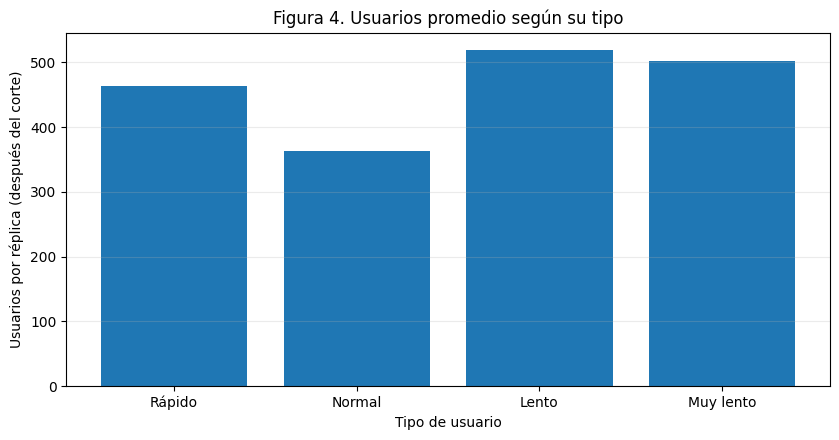

Análisis: en esta gráfica se observa la distribución simulada de los usuarios.
El 27,5 % para lentos y muy lentos es un supuesto, no una cifra del profesor.


In [7]:
tipos_base = por_tipo.query('escenario == "3 cajas · fila más corta"')
tabla_tipos = tipos_base.groupby('tipo', as_index=False).agg(
    cantidad_media=('cantidad','mean'),
    espera_media_min=('espera_media_min','mean'))
tabla_tipos['orden'] = tabla_tipos['tipo'].map({nombre:i for i,nombre in enumerate(TIPOS)})
tabla_tipos = tabla_tipos.sort_values('orden').drop(columns='orden')
display(tabla_tipos.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(tabla_tipos['tipo'], tabla_tipos['cantidad_media'])
ax.set(title='Figura 4. Usuarios promedio según su tipo',
       ylabel='Usuarios por réplica (después del corte)', xlabel='Tipo de usuario')
ax.grid(axis='y', alpha=.25); fig.tight_layout()
fig.savefig('Figura_04_Usuarios_Por_Tipo.png', dpi=200)
plt.show()
print('Análisis: en esta gráfica se observa la distribución simulada de los usuarios.')
print('El 27,5 % para lentos y muy lentos es un supuesto, no una cifra del profesor.')

## 8. Punto 3: estrategia para mejorar el servicio

Como criterio propio del ejercicio propongo que la **espera media sea de máximo 5 minutos**, y que **menos del 10 %** de las personas espere más de cinco minutos. Estas metas **no aparecen en el enunciado**; sirven para decidir de forma consistente y se pueden cambiar si el profesor indica otra condición.

Comparo primero las tres cajas bien organizadas con la asignación aleatoria y cuatro cajas. Luego reviso qué ocurre en la prueba de demanda triple. La comparación permite justificar si abrir otra caja aporta suficiente beneficio.

,escenario,espera_media_min,IC95_inf,IC95_sup,p90_espera_min,pct_mas_5_min,cumple_meta
0,3 cajas · fila más corta,0.19,0.15,0.22,0.00,1.35,True
1,3 cajas · elección aleatoria,1.49,1.39,1.58,5.30,10.59,False
2,4 cajas · fila más corta,0.03,0.02,0.05,0.00,0.25,True
3,3 cajas · demanda triple,4.38,3.85,4.92,13.95,29.11,False
4,4 cajas · demanda triple,1.10,0.98,1.22,3.84,7.95,True


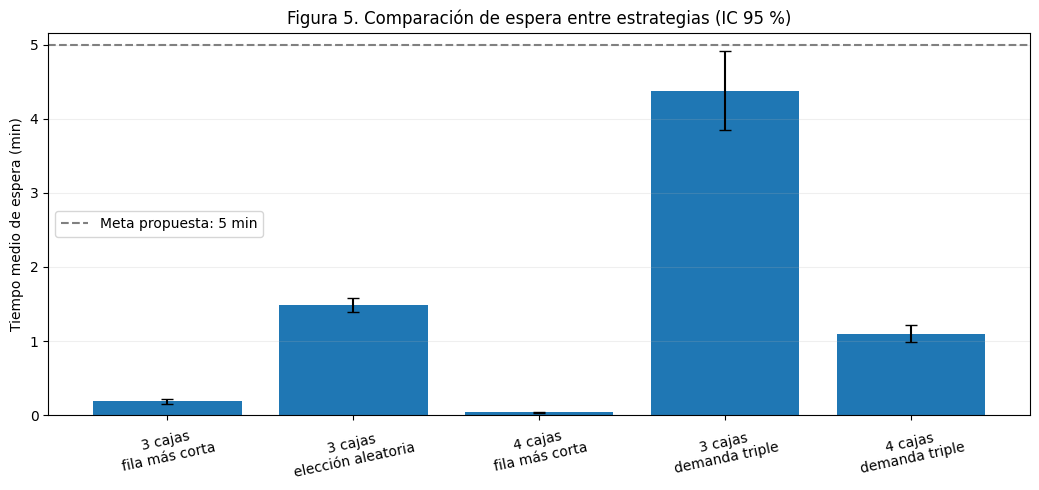

3 cajas y fila más corta: 0.19 min
3 cajas y elección aleatoria: 1.49 min
4 cajas y fila más corta: 0.03 min
Recomendación orientativa: organizar bien las tres filas antes de comprar otra caja;
si la demanda aumenta, revisar si cuatro cajas cumplen mejor las metas propuestas.


In [8]:
filas_resumen = []
for nombre, grupo in replicas.groupby('escenario', sort=False):
    media, li, ls = intervalo_95(grupo['espera_media_min'])
    filas_resumen.append({
        'escenario': nombre, 'espera_media_min': media,
        'IC95_inf': li, 'IC95_sup': ls,
        'p90_espera_min': grupo['espera_p90_min'].mean(),
        'pct_mas_5_min': 100 * grupo['proporcion_espera_mayor_5'].mean()
    })
comparacion = pd.DataFrame(filas_resumen)
comparacion['cumple_meta'] = ((comparacion['espera_media_min'] <= 5) &
                            (comparacion['pct_mas_5_min'] < 10))
display(comparacion.round(2))

fig, ax = plt.subplots(figsize=(10.5, 5.0))
xx = np.arange(len(comparacion))
valores = comparacion.espera_media_min.to_numpy()
yerr = [valores-comparacion.IC95_inf.to_numpy(),
        comparacion.IC95_sup.to_numpy()-valores]
ax.bar(xx, valores, yerr=yerr, capsize=4)
ax.axhline(5, linestyle='--', color='gray', label='Meta propuesta: 5 min')
ax.set_xticks(xx, [s.replace(' · ', '\n') for s in comparacion.escenario], rotation=12)
ax.set(title='Figura 5. Comparación de espera entre estrategias (IC 95 %)',
       ylabel='Tiempo medio de espera (min)')
ax.grid(axis='y', alpha=.2); ax.legend(); fig.tight_layout()
fig.savefig('Figura_05_Comparacion_Estrategias.png', dpi=200)
plt.show()

base = comparacion.set_index('escenario')
print(f"3 cajas y fila más corta: {base.loc['3 cajas · fila más corta', 'espera_media_min']:.2f} min")
print(f"3 cajas y elección aleatoria: {base.loc['3 cajas · elección aleatoria', 'espera_media_min']:.2f} min")
print(f"4 cajas y fila más corta: {base.loc['4 cajas · fila más corta', 'espera_media_min']:.2f} min")
print('Recomendación orientativa: organizar bien las tres filas antes de comprar otra caja;')
print('si la demanda aumenta, revisar si cuatro cajas cumplen mejor las metas propuestas.')

## 9. Punto 4: verificación, calibración y validación

Aquí distingo tres acciones:

- **Verificación:** compruebo que el programa calcule bien: esperas no negativas, inicio posterior a la llegada y que un cajero no atienda a dos personas a la vez.
- **Calibración:** reviso si los datos generados se parecen a las medias y proporciones que fijé. Como no tengo registros reales, **no puedo ajustar el modelo contra mediciones del centro comercial**.
- **Validación:** reviso que el comportamiento tenga sentido (más demanda suele aumentar las filas). Esta es solo una **validación lógica limitada**, no una validación de campo.

La gráfica compara los tiempos medios esperados de servicio con los observados en la simulación, para que la comprobación quede visible.

Verificación: no hay esperas negativas ni servicios simultáneos en el mismo cajero.


,tipo,servicio_esperado,servicio_observado,probabilidad_fijada,probabilidad_observada
0,Rápido,1.0,0.962,0.250,0.258
1,Normal,3.0,3.058,0.200,0.188
2,Lento,4.0,3.976,0.275,0.276
3,Muy lento,6.0,5.619,0.275,0.279


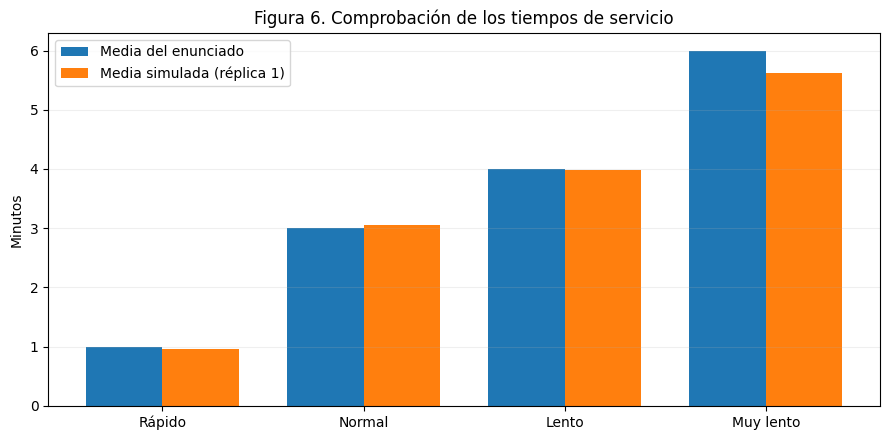

Validación lógica: comparar la Figura 5 entre demanda normal y demanda triple.
No se realizó validación con datos reales porque el enunciado no los aporta.


In [9]:
# VERIFICACIÓN: cálculo y orden de los servicios
comprobacion = simular_cajeros(muestra_calibracion, 3)
assert (comprobacion['espera_min'] >= -1e-9).all()
assert (comprobacion['inicio_min'] >= comprobacion['llegada_min'] - 1e-9).all()
assert (comprobacion['fin_min'] >= comprobacion['inicio_min']).all()
for cajero, grupo in comprobacion.groupby('cajero'):
    g = grupo.sort_values('inicio_min')
    assert (g['inicio_min'].to_numpy()[1:] >= g['fin_min'].to_numpy()[:-1]-1e-9).all()
print('Verificación: no hay esperas negativas ni servicios simultáneos en el mismo cajero.')

# CALIBRACIÓN DE ENTRADAS: contrasto los valores esperados y generados.
referencia_servicio = SERVICIO_MEDIO
observado = (muestra_calibracion.groupby('tipo')['servicio_min']
              .mean().reindex(TIPOS).to_numpy())
proporcion_observada = (muestra_calibracion['tipo'].value_counts(normalize=True)
                        .reindex(TIPOS).to_numpy())
calibracion = pd.DataFrame({'tipo': TIPOS, 'servicio_esperado': referencia_servicio,
                             'servicio_observado': observado,
                             'probabilidad_fijada': PROB,
                             'probabilidad_observada': proporcion_observada})
display(calibracion.round(3))

fig, ax = plt.subplots(figsize=(9,4.5))
pos = np.arange(4)
ax.bar(pos-0.19, referencia_servicio, width=.38, label='Media del enunciado')
ax.bar(pos+0.19, observado, width=.38, label='Media simulada (réplica 1)')
ax.set_xticks(pos, TIPOS)
ax.set(title='Figura 6. Comprobación de los tiempos de servicio', ylabel='Minutos')
ax.legend(); ax.grid(axis='y', alpha=.2); fig.tight_layout()
fig.savefig('Figura_06_Verificacion_Entradas.png', dpi=200)
plt.show()

print('Validación lógica: comparar la Figura 5 entre demanda normal y demanda triple.')
print('No se realizó validación con datos reales porque el enunciado no los aporta.')

**Análisis de la figura 6**

Al comparar los tiempos del enunciado con los resultados de la simulación, observé que los valores son bastante cercanos. Por ejemplo, el tiempo esperado de los usuarios normales es de tres minutos y el resultado simulado fue de 3,058 minutos.

Esta comparación me permitió comprobar que el programa genera tiempos acordes con los parámetros establecidos. Sin embargo, no fue posible realizar una calibración con datos reales porque el ejercicio no proporciona registros del centro comercial.

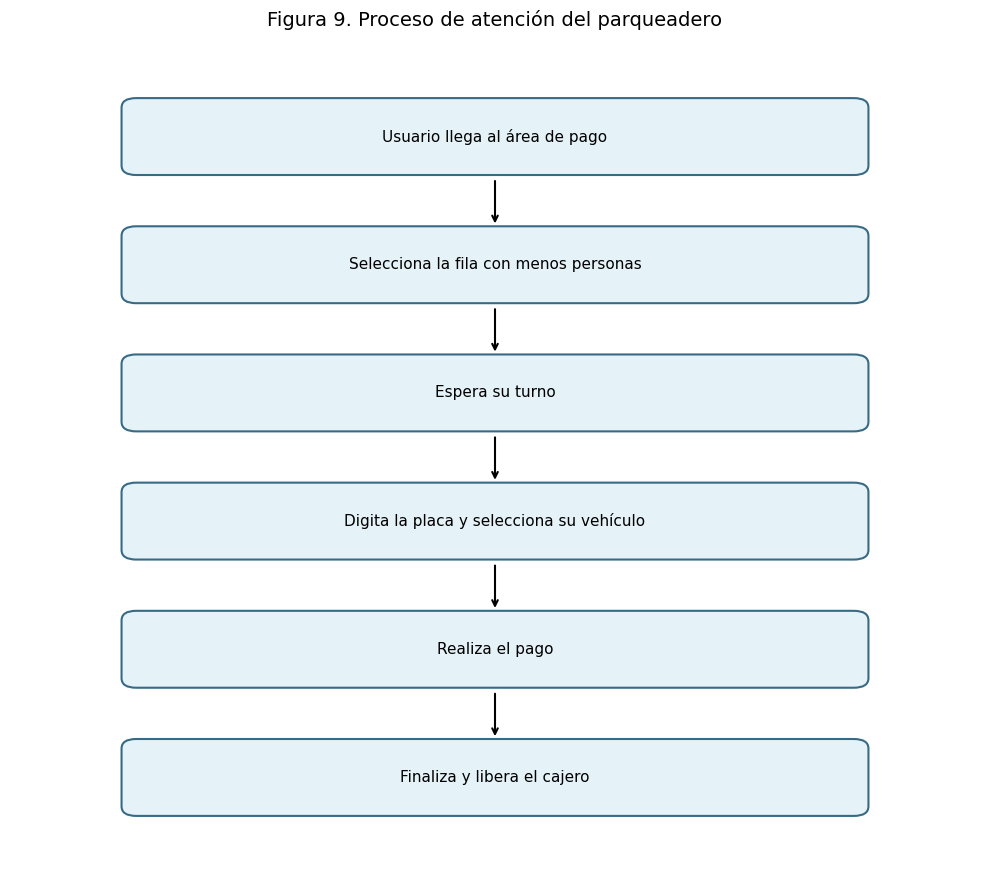

In [15]:

# Figura 9. Proceso de atención en los cajeros del parqueadero

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pasos = [
    "Usuario llega al área de pago",
    "Selecciona la fila con menos personas",
    "Espera su turno",
    "Digita la placa y selecciona su vehículo",
    "Realiza el pago",
    "Finaliza y libera el cajero"
]

fig, ax = plt.subplots(figsize=(10, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 13)
ax.axis('off')

for i, paso in enumerate(pasos):
    y = 11.6 - i * 2

    cuadro = FancyBboxPatch(
        (1.3, y - 0.45), 7.4, 0.9,
        boxstyle="round,pad=0.15",
        facecolor="#E5F2F8",
        edgecolor="#376B85",
        linewidth=1.5
    )

    ax.add_patch(cuadro)
    ax.text(5, y, paso, ha='center', va='center', fontsize=11)

    if i < len(pasos) - 1:
        ax.annotate(
            '', xy=(5, y - 1.4), xytext=(5, y - 0.65),
            arrowprops=dict(arrowstyle='->', lw=1.5)
        )

ax.set_title(
    'Figura 9. Proceso de atención del parqueadero',
    fontsize=14, pad=15
)

fig.tight_layout()
fig.savefig('Figura_09_Proceso_Parqueadero.png',
            dpi=200, bbox_inches='tight')
plt.show()


## Análisis de la figura 9
En esta figura representé el proceso de atención del parqueadero desde que el usuario llega al área de pago hasta que finaliza la transacción. Primero el usuario selecciona la fila con menos personas, luego espera su turno, digita la placa, selecciona el vehículo, realiza el pago y finalmente libera el cajero.

Este diagrama me permitió mostrar de forma más clara la lógica del modelo simulado, ya que resume las etapas que sigue cada vehículo dentro del sistema de pago. Además, ayuda a entender por qué el tiempo de espera depende tanto de la cantidad de usuarios en fila como del tiempo que cada persona tarda en completar el pago.

## 10. Punto 5: eliminar el período transitorio y comparar antes y después

La Figura 1 permitió elegir cuántos vehículos iniciales descartar. Ahora presento los resultados **con toda la corrida** y **sin los primeros vehículos**, usando exactamente las mismas réplicas.

La gráfica ayuda a ver si empezar con el sistema vacío afecta los promedios. Si el cambio es pequeño, también es un resultado válido: significa que con este nivel de carga el período inicial tiene poco efecto. Si no se detectó estabilidad en el paso 3, la comparación queda indicada como exploratoria.

,Medición,Espera media (min)
0,Antes de eliminar,0.184
1,Después de eliminar,0.186


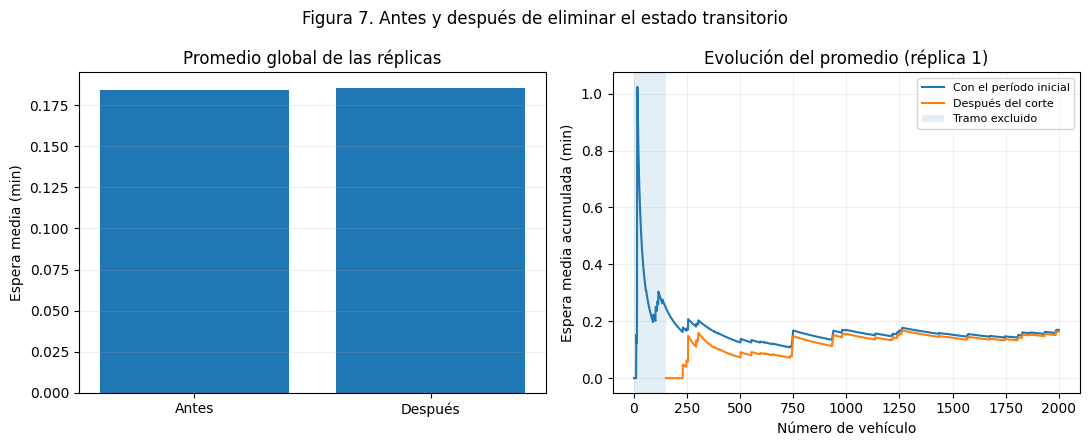

Antes: 0.184 min | Después: 0.186 min
Diferencia: +0.001 minutos


In [10]:
media_antes = antes_despues['antes_min'].mean()
media_despues = antes_despues['despues_min'].mean()
display(pd.DataFrame({'Medición': ['Antes de eliminar', 'Después de eliminar'],
                      'Espera media (min)': [media_antes, media_despues]}).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
ejes[0].bar(['Antes', 'Después'], [media_antes, media_despues])
ejes[0].set(title='Promedio global de las réplicas', ylabel='Espera media (min)')
ejes[0].grid(axis='y', alpha=.2)

muestra = simular_cajeros(generar_vehiculos(VEHICULOS_POR_REPLICA, SEMILLA+30001), 3)
serie_total = muestra['espera_min'].expanding().mean().to_numpy()
serie_ajustada = muestra['espera_min'].iloc[CORTE:].expanding().mean().to_numpy()
ejes[1].plot(np.arange(1,len(serie_total)+1), serie_total, label='Con el período inicial')
ejes[1].plot(np.arange(CORTE+1,len(serie_total)+1), serie_ajustada, label='Después del corte')
ejes[1].axvspan(0, CORTE, alpha=.12, label='Tramo excluido')
ejes[1].set(title='Evolución del promedio (réplica 1)',
            xlabel='Número de vehículo', ylabel='Espera media acumulada (min)')
ejes[1].legend(fontsize=8); ejes[1].grid(alpha=.2)
fig.suptitle('Figura 7. Antes y después de eliminar el estado transitorio')
fig.tight_layout(); fig.savefig('Figura_07_Antes_Despues.png', dpi=200)
plt.show()
print(f'Antes: {media_antes:.3f} min | Después: {media_despues:.3f} min')
print(f'Diferencia: {media_despues-media_antes:+.3f} minutos')
if not ESTABILIDAD_DETECTADA:
    print('AVISO: no se debe llamar estable al modelo sin más comprobaciones.')

**Análisis de la figura 7**

En esta gráfica comparé los resultados antes y después de retirar los primeros 150 vehículos de la simulación.

El tiempo promedio de espera pasó de 0,184 a 0,186 minutos. La diferencia fue menor a 0,01 minutos, por lo que el cambio es muy pequeño.

Esto me permitió observar que, en las condiciones simuladas, el período inicial tiene poca influencia sobre el promedio general. Sin embargo, el corte de 150 vehículos es una estimación basada en la gráfica y no demuestra por sí solo que el sistema alcanzó un estado estable.

## 11. Sensibilidad al reparto de usuarios lentos y muy lentos

El enunciado no dice cómo se divide el 55 % restante. Por eso comparo el supuesto principal (27,5 % y 27,5 %) con dos opciones: 35 % lentos y 20 % muy lentos, o 20 % lentos y 35 % muy lentos. Mantengo 25 % rápidos y 20 % normales. Esto sirve para comprobar si nuestra decisión depende demasiado de un dato que no se proporcionó.

,supuesto,espera_media_min
0,20 % lentos / 35 % muy lentos,0.226
1,"27,5 % lentos / 27,5 % muy lentos",0.210
2,35 % lentos / 20 % muy lentos,0.194


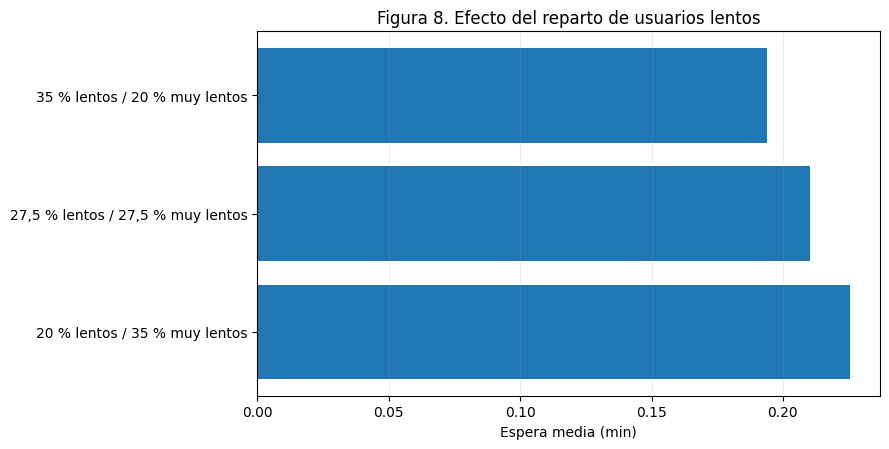

In [11]:
PROB_PRUEBAS = {
    '27,5 % lentos / 27,5 % muy lentos': [0.25, 0.20, 0.275, 0.275],
    '35 % lentos / 20 % muy lentos': [0.25, 0.20, 0.35, 0.20],
    '20 % lentos / 35 % muy lentos': [0.25, 0.20, 0.20, 0.35],
}
filas_sensibilidad = []
for nombre, probabilidades in PROB_PRUEBAS.items():
    for r in range(1, min(NUM_REPLICAS, 25)+1):
        veh = generar_vehiculos(VEHICULOS_POR_REPLICA, SEMILLA+50000+r,
                                probabilidades=probabilidades)
        datos = simular_cajeros(veh, 3)
        filas_sensibilidad.append({'supuesto':nombre,'replica':r,
            'espera_media_min':datos['espera_min'].iloc[CORTE:].mean()})
sensibilidad = pd.DataFrame(filas_sensibilidad)
resumen_sensibilidad = sensibilidad.groupby('supuesto', as_index=False)['espera_media_min'].mean()
display(resumen_sensibilidad.round(3))

fig, ax = plt.subplots(figsize=(9,4.6))
ax.barh(resumen_sensibilidad['supuesto'], resumen_sensibilidad['espera_media_min'])
ax.set(title='Figura 8. Efecto del reparto de usuarios lentos', xlabel='Espera media (min)')
ax.grid(axis='x', alpha=.2); fig.tight_layout()
fig.savefig('Figura_08_Sensibilidad_Tipos.png', dpi=200)
plt.show()

**Análisis de la figura 8**

Al modificar las probabilidades de los usuarios lentos y muy lentos, observé que el tiempo de espera también cambia.

Cuando aumenté la proporción de usuarios muy lentos al 35 %, la espera promedio fue de 0,226 minutos. Cuando esa proporción bajó al 20 %, la espera fue de 0,194 minutos.

Esto muestra que los usuarios que requieren más tiempo para realizar el pago pueden influir en el funcionamiento de los cajeros. También es importante aclarar que estas proporciones fueron supuestos del ejercicio, porque el profesor no especificó cómo distribuir el 55 % restante de usuarios.

## 12. Conclusiones y descarga de resultados

En este ejercicio aprendí que el tiempo de atención y el tiempo de espera no son iguales. También observé que las decisiones no deben basarse en una sola corrida: primero es necesario revisar el estado estable, definir un período inicial de descarte y utilizar varias réplicas para obtener promedios más confiables.

La **estrategia** debe apoyarse en las gráficas anteriores. Si los tres cajeros cumplen las metas propuestas, es razonable conservarlos y orientar a cada usuario hacia la fila menos ocupada. Si se presentan aumentos importantes de vehículos, conviene volver a estudiar la capacidad y considerar un cuarto cajero. Es una recomendación **académica**, porque no se conocen costos reales ni datos horarios del centro comercial.

**Limitaciones:** la proporción de lentos y muy lentos, la corriente global de llegadas, las metas de servicio y el aumento de demanda son supuestos que expliqué. Además, no se dispone de registros reales para validar el modelo fuera del aula.

Los CSV y las imágenes que guarda la última celda sirven como evidencias para el informe Word y para GitHub.

In [12]:
replicas.to_csv('01_Replicas_Parqueadero.csv', index=False, encoding='utf-8-sig')
por_tipo.to_csv('02_Usuarios_Por_Tipo.csv', index=False, encoding='utf-8-sig')
por_cajero.to_csv('03_Resultados_Por_Cajero.csv', index=False, encoding='utf-8-sig')
comparacion.to_csv('04_Comparacion_Estrategias.csv', index=False, encoding='utf-8-sig')
antes_despues.to_csv('05_Antes_Despues_Transitorio.csv', index=False, encoding='utf-8-sig')
tabla_precision.to_csv('06_Calculo_Numero_Replicas.csv', index=False, encoding='utf-8-sig')
sensibilidad.to_csv('07_Sensibilidad_Usuarios.csv', index=False, encoding='utf-8-sig')
muestra_vehiculos.to_csv('08_Ejemplo_Vehiculos.csv', index=False, encoding='utf-8-sig')

print('Archivos CSV generados correctamente.')
print('Se guardaron también ocho gráficas PNG, una por cada análisis.')
print('En Google Colab: menú lateral izquierdo → Archivos → actualizar → descargar.')
import platform
print('Versión de Python:', platform.python_version())
print('NumPy:', np.__version__, '| Pandas:', pd.__version__)

Archivos CSV generados correctamente.
Se guardaron también ocho gráficas PNG, una por cada análisis.
En Google Colab: menú lateral izquierdo → Archivos → actualizar → descargar.
Versión de Python: 3.13.18
NumPy: 2.4.6 | Pandas: 2.2.3
